# IPP Practical Submission

**Student Name:** Neil Tailor  
**Enrollment Number:** 20251037
**Subject:** Image Processing (IPP)

> **How to use:** Keep this notebook in a folder with your image files (if you have them), install the required libraries, and select **Kernel → Restart & Run All**. If an input image is not present, the notebook creates or uses a sample image so that the practical can still be demonstrated. Replace the sample with your own image when required by your instructor.

**Required libraries:** `opencv-python`, `numpy`, `matplotlib`, `Pillow`, `scikit-image` (File 1 uses the first four; File 2 uses all listed libraries).

Install once in a terminal using:
```bash
pip install opencv-python numpy matplotlib pillow scikit-image jupyter
```

---

# IPP Practical File 1 (Assignment 2)


Code with explanation for the 10 problem statements. The setup cell creates sample images only if the named files are missing; put your own `flower.jpg`, `scene.jpg`, `sunset.png`, `car.jpg`, `img1.jpg` and `img2.jpg` in the same folder to use real images.

## Setup

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# --- Sample-image makers: used ONLY if the named file is missing, so the notebook always runs ---
def make_flower():
    img = np.zeros((400, 400, 3), np.uint8); img[:] = (60, 140, 70)
    for a in np.linspace(0, 2 * np.pi, 8, endpoint=False):
        cv2.circle(img, (int(200 + 80 * np.cos(a)), int(200 + 80 * np.sin(a))), 55, (180, 90, 230), -1)
    cv2.circle(img, (200, 200), 45, (30, 200, 240), -1)
    return img

def make_scene():
    img = np.zeros((400, 400, 3), np.uint8)
    for i in range(400): img[i, :] = (255 - i // 3, 200 - i // 5, 120)       # sky gradient (BGR)
    cv2.rectangle(img, (0, 280), (400, 400), (60, 150, 60), -1)             # ground
    cv2.rectangle(img, (120, 180), (280, 320), (90, 120, 200), -1)          # house
    cv2.fillPoly(img, [np.array([(100, 180), (200, 100), (300, 180)])], (40, 40, 160))
    cv2.circle(img, (340, 60), 30, (0, 220, 255), -1)                        # sun
    cv2.putText(img, "IPP", (150, 270), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (255, 255, 255), 3)
    return img

def make_sunset():
    img = np.zeros((300, 450, 3), np.uint8)
    for i in range(300): img[i, :] = (120 + i // 3, 60 + i // 2, 255 - i // 2)
    cv2.circle(img, (225, 230), 60, (0, 200, 255), -1)
    return img

def make_car():
    img = np.full((300, 450, 3), (235, 215, 190), np.uint8)
    cv2.rectangle(img, (40, 150), (400, 230), (40, 40, 200), -1)
    cv2.rectangle(img, (120, 100), (330, 150), (40, 40, 200), -1)
    cv2.rectangle(img, (140, 110), (230, 148), (240, 220, 160), -1)
    cv2.circle(img, (110, 235), 32, (30, 30, 30), -1); cv2.circle(img, (330, 235), 32, (30, 30, 30), -1)
    cv2.putText(img, "CAR", (260, 205), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3)
    return img

def make_img1():
    return cv2.cvtColor(make_scene(), cv2.COLOR_BGR2GRAY)

def make_img2():
    rng = np.random.default_rng(0)
    return np.clip(make_img1() + rng.normal(0, 12, (400, 400)), 0, 255).astype(np.uint8)

def ensure(name, maker):
    if not os.path.exists(name):
        cv2.imwrite(name, maker())
        print(f"'{name}' not found -> created a sample image. Put your own file with this name to use real data.")

for fname, maker in [("flower.jpg", make_flower), ("scene.jpg", make_scene), ("sunset.png", make_sunset),
                     ("car.jpg", make_car), ("img1.jpg", make_img1), ("img2.jpg", make_img2)]:
    ensure(fname, maker)

def to_rgb(bgr):
    """OpenCV loads images as BGR; Matplotlib expects RGB."""
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
print("Setup complete.")

Setup complete.


## Problem 1
**Read an image with OpenCV and display it in a window titled "Original Image"**

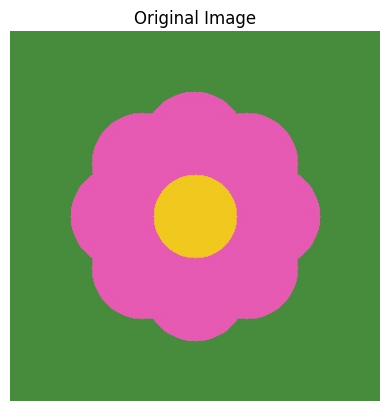

In [2]:
img = cv2.imread("flower.jpg")  # OpenCV reads the image in BGR format
if img is None:
    raise FileNotFoundError("flower.jpg not found")

# Jupyter/Colab notebooks generally cannot open a separate desktop window.
# In a normal local Python session, display the required OpenCV window.
try:
    from IPython import get_ipython
    running_in_notebook = get_ipython() is not None
except Exception:
    running_in_notebook = False

if running_in_notebook:
    plt.imshow(to_rgb(img))
    plt.title("Original Image")
    plt.axis("off")
    plt.show()
else:
    cv2.imshow("Original Image", img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

**Explanation:** `cv2.imread()` loads the file into a NumPy array and returns `None` if the path is wrong, so the code checks for that first. `cv2.imshow()` opens a window whose title is the first argument, `cv2.waitKey(0)` keeps it open until a key is pressed, and `cv2.destroyAllWindows()` closes it. Jupyter and Google Colab cannot open GUI windows, so the `except` branch shows the same image with Matplotlib. Because OpenCV stores colours as BGR, the image is converted to RGB before Matplotlib displays it.

## Problem 2
**Print the dimensions (height, width, channels) and data type of "scene.jpg"**

In [3]:
img = cv2.imread("scene.jpg")
if img is None:
    raise FileNotFoundError("scene.jpg not found")
height, width, channels = img.shape
print("Height  :", height)
print("Width   :", width)
print("Channels:", channels)
print("Data type:", img.dtype)

Height  : 400
Width   : 400
Channels: 3
Data type: uint8


**Explanation:** An image read by OpenCV is a NumPy array, and its `shape` attribute is `(height, width, channels)`. A colour image has 3 channels (B, G, R). The `dtype` attribute gives the data type of each value; `uint8` means unsigned 8-bit integers, so every pixel value lies between 0 and 255.

## Problem 3
**Convert a colour image to grayscale and save it as "output_gray.jpg"**

Saved output_gray.jpg, shape: (400, 400)


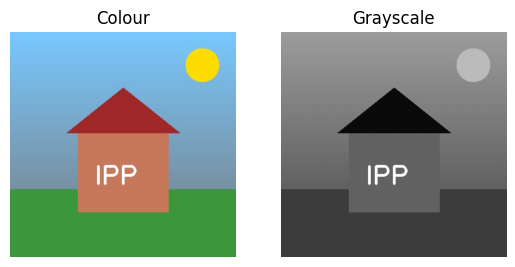

In [4]:
img = cv2.imread("scene.jpg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)         # weighted sum of B, G, R channels
cv2.imwrite("output_gray.jpg", gray)                 # save the result to disk
print("Saved output_gray.jpg, shape:", gray.shape)
plt.subplot(1, 2, 1); plt.imshow(to_rgb(img)); plt.title("Colour"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(gray, cmap="gray"); plt.title("Grayscale"); plt.axis("off")
plt.show()

**Explanation:** `cv2.cvtColor()` with `COLOR_BGR2GRAY` replaces the three colour channels with a single intensity value per pixel, computed as 0.299 R + 0.587 G + 0.114 B, which matches how bright each colour looks to the human eye. The result is a 2-D array, which `cv2.imwrite()` saves as `output_gray.jpg`. The plot shows the colour and gray versions side by side.

## Problem 4
**Open "sunset.png" using Pillow and display it**

Format: PNG | Size: (450, 300) | Mode: RGB


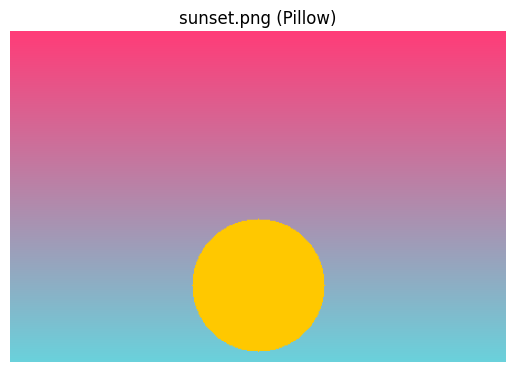

In [5]:
from PIL import Image
im = Image.open("sunset.png")                        # Pillow opens the file lazily
print("Format:", im.format, "| Size:", im.size, "| Mode:", im.mode)
# im.show()  # opens the default image viewer on a normal desktop
plt.imshow(im); plt.title("sunset.png (Pillow)"); plt.axis("off"); plt.show()

**Explanation:** Pillow is another image library; `Image.open()` reads the file and gives an `Image` object with useful properties such as `format`, `size` (width, height) and `mode` (for example RGB). `im.show()` hands the image to the operating system's viewer, which does not work inside a notebook, so Matplotlib is used for display here. Pillow loads images in RGB order, so no colour conversion is needed.

## Problem 5
**Resize an image to 50% of its original width and height using OpenCV**

Original: (400, 400) -> Resized: (200, 200)


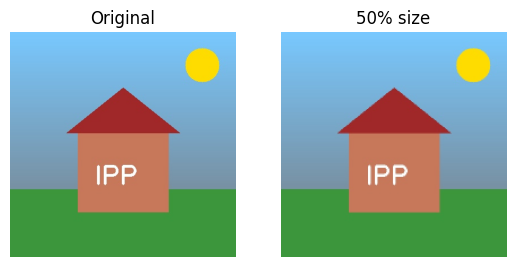

In [6]:
img = cv2.imread("scene.jpg")
resized = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
print("Original:", img.shape[:2], "-> Resized:", resized.shape[:2])
plt.subplot(1, 2, 1); plt.imshow(to_rgb(img)); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(to_rgb(resized)); plt.title("50% size"); plt.axis("off")
plt.show()

**Explanation:** `cv2.resize()` can scale by factors: with the output size set to `None`, the arguments `fx` and `fy` give the scale along the width and height. Both are 0.5, so the image has half the width and half the height (a quarter of the pixels). `INTER_AREA` is the interpolation method recommended for shrinking, because it averages the source pixels and reduces aliasing.

## Problem 6
**Crop the central 200x200 pixel area of an image and display it using Matplotlib**

Cropped shape: (200, 200, 3)


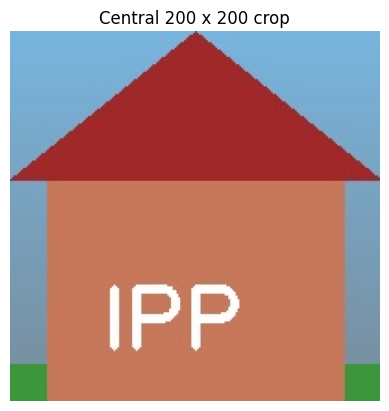

In [7]:
img = cv2.imread("scene.jpg")
h, w = img.shape[:2]
cy, cx = h // 2, w // 2                              # centre of the image
crop = img[cy - 100: cy + 100, cx - 100: cx + 100]   # 200 x 200 block around the centre
print("Cropped shape:", crop.shape)
plt.imshow(to_rgb(crop)); plt.title("Central 200 x 200 crop"); plt.axis("off"); plt.show()

**Explanation:** Because an image is a NumPy array, cropping is just slicing with `[rows, columns]`. The centre pixel is found from half the height and half the width. Taking 100 pixels on each side of the centre in both directions gives a 200 x 200 region. The image must be at least 200 pixels in each direction for this to work.

## Problem 7
**Rotate an image by 90 degrees clockwise using OpenCV**

Original: (400, 400, 3) -> Rotated: (400, 400, 3)


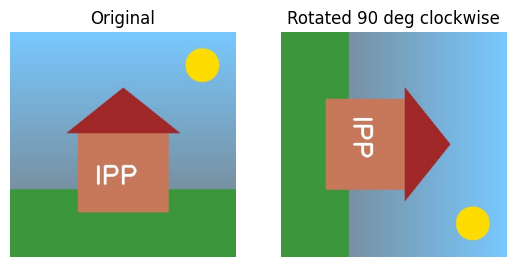

In [8]:
img = cv2.imread("scene.jpg")
rotated = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
print("Original:", img.shape, "-> Rotated:", rotated.shape)
plt.subplot(1, 2, 1); plt.imshow(to_rgb(img)); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(to_rgb(rotated)); plt.title("Rotated 90 deg clockwise"); plt.axis("off")
plt.show()

**Explanation:** `cv2.rotate()` performs exact rotations by multiples of 90 degrees without interpolation, so no quality is lost. The flag `ROTATE_90_CLOCKWISE` turns the image to the right. Width and height are swapped in the output (visible in the printed shapes when the image is not square).

## Problem 8
**Flip the image "car.jpg" left-to-right using OpenCV and display the result**

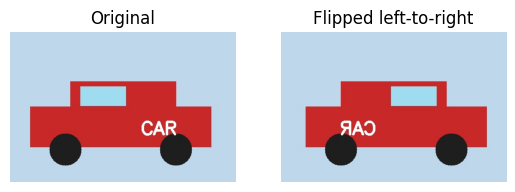

In [9]:
img = cv2.imread("car.jpg")
flipped = cv2.flip(img, 1)                           # 1 = flip around the vertical axis (horizontal flip)
plt.subplot(1, 2, 1); plt.imshow(to_rgb(img)); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(to_rgb(flipped)); plt.title("Flipped left-to-right"); plt.axis("off")
plt.show()

**Explanation:** `cv2.flip(img, flipCode)` mirrors the image. A flip code of 1 flips horizontally (left to right), 0 flips vertically (top to bottom) and -1 flips in both directions. The text on the car appears reversed in the output, which confirms the horizontal mirror.

## Problem 9
**Convert an image from RGB to HSV and display Hue, Saturation and Value separately**

Hue range: 0 - 179 | Saturation range: 0 - 255 | Value range: 87 - 255


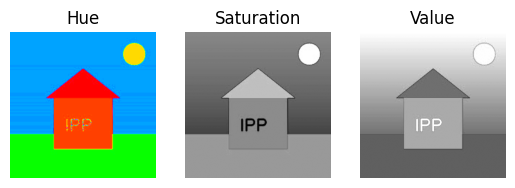

In [10]:
img = cv2.imread("scene.jpg")
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
H, S, V = cv2.split(hsv)
print("Hue range:", H.min(), "-", H.max(), "| Saturation range:", S.min(), "-", S.max(), "| Value range:", V.min(), "-", V.max())
titles = ["Hue", "Saturation", "Value"]
cmaps = ["hsv", "gray", "gray"]
for i, (ch, t, c) in enumerate(zip([H, S, V], titles, cmaps), 1):
    plt.subplot(1, 3, i); plt.imshow(ch, cmap=c); plt.title(t); plt.axis("off")
plt.show()

**Explanation:** HSV describes colour in a way closer to human perception: Hue is the type of colour, Saturation is how pure or vivid it is, and Value is how bright it is. `cv2.cvtColor()` with `COLOR_RGB2HSV` does the conversion and `cv2.split()` separates the three channels. In OpenCV, Hue is stored from 0 to 179 (half of 360 degrees) so that it fits in 8 bits, while Saturation and Value range from 0 to 255. Each channel is shown as a separate image.

## Problem 10
**Compute the Mean Squared Error (MSE) between two grayscale images**

In [11]:
img1 = cv2.imread("img1.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float64)
img2 = cv2.imread("img2.jpg", cv2.IMREAD_GRAYSCALE).astype(np.float64)
assert img1.shape == img2.shape, "Images must have the same size"
mse = np.mean((img1 - img2) ** 2)
print("MSE between img1.jpg and img2.jpg:", round(mse, 4))

MSE between img1.jpg and img2.jpg: 149.5979


**Explanation:** MSE is the average of the squared pixel-by-pixel differences: MSE = (1 / MN) x sum of (I1 - I2)^2. The images are converted to `float64` first, because subtracting `uint8` arrays would wrap around below zero and give wrong results. Both images must have the same size. An MSE of 0 means identical images, and larger values mean a bigger difference.